In [2]:
%pip install kmodes scikit-learn pandas numpy matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from kmodes.kprototypes import KPrototypes

RANDOM_STATE = 42
DATA_PATH = Path("modified_dataset.csv")
OUTPUT_DIR = Path("ml_clustering_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}.  "
        "or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
display(df.head())

Loaded 3,900 rows and 36 columns


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,...,age_group,r_score,f_score,m_score,rfm_total,rfm_segment,loyalty_def1,loyalty_def2,is_loyal,customer_segment
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,55-70,3,2,3,8,Needs Attention,0,0,0,Subscription Member
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,18-24,3,1,3,7,Needs Attention,0,0,0,Subscription Member
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,45-54,5,3,4,12,Loyal,0,0,0,Subscription Member
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,18-24,5,5,5,15,Champions,1,0,0,Subscription Member
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,45-54,1,4,2,7,Needs Attention,1,0,0,Subscription Member


In [4]:
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())
print("Total missing cells:", int(df.isna().sum().sum()))
print("Existing rule-based segments:")
display(df["customer_segment"].value_counts().to_frame("customers"))

assert df["customer_id"].is_unique, "Expected one row per customer_id."


Duplicate customer IDs: 0
Total missing cells: 0
Existing rule-based segments:


,customers
customer_segment,
Passive Buyer,1830
Subscription Member,1053
Promo Hunter,624
Brand Advocate,393


In [5]:
numeric_cols = [
    "age",
    "purchase_amount",
    "previous_purchases",
    "review_rating",
]

categorical_cols = [
    "gender",
    "category",
    "season",
    "subscription_status",
    "promo_code_used",
    "frequency_of_purchases",
    "payment_method",
]

required_cols = numeric_cols + categorical_cols
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

cluster_data = df[required_cols].copy()

# Make numeric columns numeric and handle missing values defensively.
for col in numeric_cols:
    cluster_data[col] = pd.to_numeric(cluster_data[col], errors="coerce")
    cluster_data[col] = cluster_data[col].fillna(cluster_data[col].median())

# K-Prototypes expects categorical values to be strings, without nulls.
for col in categorical_cols:
    cluster_data[col] = cluster_data[col].fillna("Unknown").astype(str)

print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)
print("Prepared shape:", cluster_data.shape)
display(cluster_data.head())

Numerical features: ['age', 'purchase_amount', 'previous_purchases', 'review_rating']
Categorical features: ['gender', 'category', 'season', 'subscription_status', 'promo_code_used', 'frequency_of_purchases', 'payment_method']
Prepared shape: (3900, 11)


,age,purchase_amount,previous_purchases,review_rating,gender,category,season,subscription_status,promo_code_used,frequency_of_purchases,payment_method
0,55,53,14,3.1,Male,Clothing,Winter,Yes,Yes,Fortnightly,Venmo
1,19,64,2,3.1,Male,Clothing,Winter,Yes,Yes,Fortnightly,Cash
2,50,73,23,3.1,Male,Clothing,Spring,Yes,Yes,Weekly,Credit Card
3,21,90,49,3.5,Male,Footwear,Spring,Yes,Yes,Weekly,PayPal
4,45,49,31,2.7,Male,Clothing,Spring,Yes,Yes,Annually,PayPal


In [6]:
scaler = StandardScaler()
X_num = scaler.fit_transform(cluster_data[numeric_cols])
X_cat = cluster_data[categorical_cols].to_numpy(dtype=object)

# One combined matrix: numeric columns first, categorical columns second.
X = np.column_stack([X_num, X_cat])
categorical_idx = list(range(len(numeric_cols), len(numeric_cols) + len(categorical_cols)))

print("Model input shape:", X.shape)
print("Categorical column indices:", categorical_idx)

Model input shape: (3900, 11)
Categorical column indices: [4, 5, 6, 7, 8, 9, 10]


K=2: cost=20,371.79
K=3: cost=18,581.87
K=4: cost=17,045.78
K=5: cost=15,914.69
K=6: cost=15,190.07
K=7: cost=14,383.21
K=8: cost=13,617.07


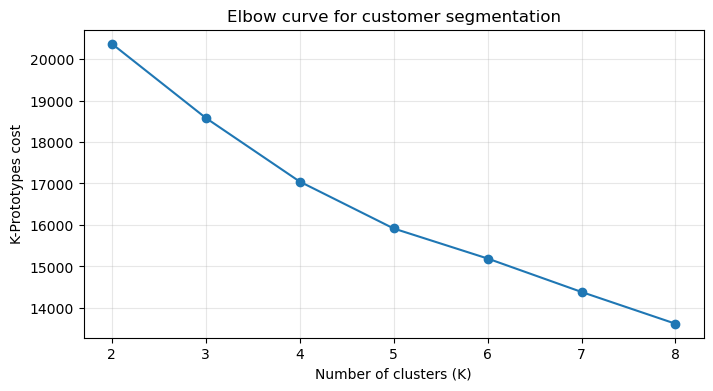

In [7]:
k_values = range(2, 9)
costs = []

for k in k_values:
    model_k = KPrototypes(
        n_clusters=k,
        init="Cao",
        n_init=3,
        max_iter=100,
        random_state=RANDOM_STATE,
        verbose=0,
        n_jobs=1,
    )
    model_k.fit_predict(X, categorical=categorical_idx)
    costs.append(model_k.cost_)
    print(f"K={k}: cost={model_k.cost_:,.2f}")

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), costs, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("K-Prototypes cost")
plt.title("Elbow curve for customer segmentation")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
SELECTED_K = 5
kproto = KPrototypes(
    n_clusters=SELECTED_K,
    init="Cao",
    n_init=5,
    max_iter=150,
    random_state=RANDOM_STATE,
    verbose=0,
    n_jobs=1,
)

cluster_labels = kproto.fit_predict(X, categorical=categorical_idx)
df["ml_cluster"] = cluster_labels

print("Selected K:", SELECTED_K)
print("Final model cost:", round(kproto.cost_, 2))
print("Gamma (numeric/categorical balance):", round(float(kproto.gamma), 4))
display(df["ml_cluster"].value_counts().sort_index().to_frame("customers"))

Selected K: 5
Final model cost: 15914.69
Gamma (numeric/categorical balance): 0.5


,customers
ml_cluster,
0,850
1,802
2,793
3,748
4,707


In [9]:
profile = df.groupby("ml_cluster").agg(
    customers=("customer_id", "count"),
    avg_age=("age", "mean"),
    avg_purchase_amount=("purchase_amount", "mean"),
    avg_previous_purchases=("previous_purchases", "mean"),
    avg_review_rating=("review_rating", "mean"),
    avg_frequency_score=("frequency_score", "mean"),
    avg_clv_proxy=("clv_proxy", "mean"),  # descriptive only; not a model input
    pct_promo=("promo_code_used_flag", "mean"),
    pct_subscribed=("subscription_status_flag", "mean"),
    pct_satisfied=("satisfaction_flag", "mean"),
).reset_index()


for col, new_name in [
    ("category", "top_category"),
    ("season", "top_season"),
    ("frequency_of_purchases", "top_purchase_frequency"),
    ("payment_method", "top_payment_method"),
]:
    modes = df.groupby("ml_cluster")[col].agg(
        lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown"
    )
    profile[new_name] = profile["ml_cluster"].map(modes)

for col in ["pct_promo", "pct_subscribed", "pct_satisfied"]:
    profile[col] = (profile[col] * 100).round(1)

round_cols = [
    "avg_age", "avg_purchase_amount", "avg_previous_purchases",
    "avg_review_rating", "avg_frequency_score", "avg_clv_proxy"
]
profile[round_cols] = profile[round_cols].round(2)
profile = profile.sort_values("avg_clv_proxy", ascending=False).reset_index(drop=True)
display(profile)

,ml_cluster,customers,avg_age,avg_purchase_amount,avg_previous_purchases,avg_review_rating,avg_frequency_score,avg_clv_proxy,pct_promo,pct_subscribed,pct_satisfied,top_category,top_season,top_purchase_frequency,top_payment_method
0,1,802,56.59,80.30,28.57,4.19,3.86,1007.11,42.3,27.1,69.1,Clothing,Fall,Annually,Credit Card
1,2,793,30.66,60.02,39.53,3.79,3.87,849.87,44.5,27.7,43.6,Clothing,Winter,Quarterly,Cash
2,3,748,38.90,75.12,14.50,3.13,4.18,787.23,42.0,27.0,5.1,Clothing,Fall,Bi-Weekly,Debit Card
3,0,850,57.17,38.96,28.82,3.40,3.87,491.53,43.3,27.9,20.1,Clothing,Spring,Quarterly,PayPal
4,4,707,34.61,44.96,13.10,4.28,4.03,432.24,42.9,25.0,74.3,Clothing,Summer,Fortnightly,Cash


In [10]:
segment_mix = pd.crosstab(
    df["ml_cluster"],
    df["customer_segment"],
    normalize="index"
).mul(100).round(1)

print("Percentage mix of existing customer segments within each ML cluster:")
display(segment_mix)

print("Value-tier mix within each ML cluster:")
value_mix = pd.crosstab(
    df["ml_cluster"],
    df["value_tier"],
    normalize="index"
).mul(100).round(1)
display(value_mix)

Percentage mix of existing customer segments within each ML cluster:


customer_segment,Brand Advocate,Passive Buyer,Promo Hunter,Subscription Member
ml_cluster,,,,
0,4.0,52.7,15.4,27.9
1,15.8,41.9,15.2,27.1
2,11.3,44.1,16.8,27.7
3,0.8,57.2,15.0,27.0
4,19.2,37.9,17.8,25.0


Value-tier mix within each ML cluster:


value_tier,High,Low,Mid,Premium
ml_cluster,,,,
0,22.1,33.9,34.4,9.6
1,23.9,14.5,15.8,45.8
2,30.6,16.4,20.3,32.7
3,27.9,19.1,23.1,29.8
4,20.4,42.3,31.3,6.1


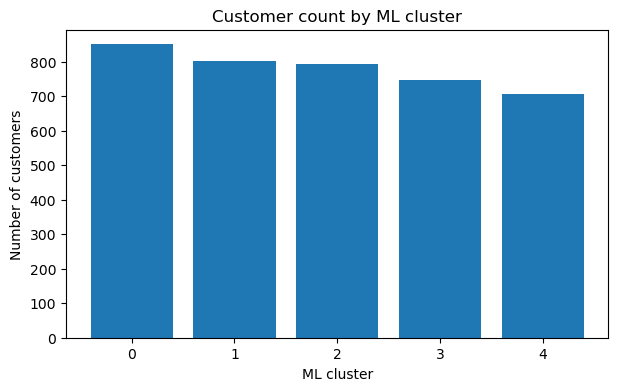

<Figure size 800x400 with 0 Axes>

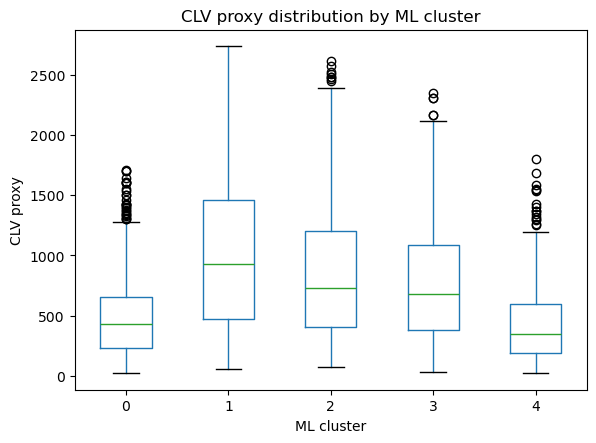

In [11]:
cluster_sizes = df["ml_cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(cluster_sizes.index.astype(str), cluster_sizes.values)
plt.xlabel("ML cluster")
plt.ylabel("Number of customers")
plt.title("Customer count by ML cluster")
plt.show()

plt.figure(figsize=(8, 4))
df.boxplot(column="clv_proxy", by="ml_cluster", grid=False)
plt.title("CLV proxy distribution by ML cluster")
plt.suptitle("")
plt.xlabel("ML cluster")
plt.ylabel("CLV proxy")
plt.show()

In [12]:
df.to_csv(OUTPUT_DIR / "customers_with_ml_clusters.csv", index=False)
profile.to_csv(OUTPUT_DIR / "ml_cluster_profiles.csv", index=False)
segment_mix.to_csv(OUTPUT_DIR / "ml_cluster_vs_rule_segments.csv")

joblib.dump(
    {
        "model": kproto,
        "scaler": scaler,
        "numeric_features": numeric_cols,
        "categorical_features": categorical_cols,
        "categorical_indices": categorical_idx,
        "selected_k": SELECTED_K,
    },
    OUTPUT_DIR / "kprototypes_customer_segmentation.joblib",
)

print("Saved files to:", OUTPUT_DIR.resolve())
print("- customers_with_ml_clusters.csv")
print("- ml_cluster_profiles.csv")
print("- ml_cluster_vs_rule_segments.csv")
print("- kprototypes_customer_segmentation.joblib")

Saved files to: /Users/kamaleshwari/Desktop/placementprep/cvs/decoding customer value/ml_clustering_outputs
- customers_with_ml_clusters.csv
- ml_cluster_profiles.csv
- ml_cluster_vs_rule_segments.csv
- kprototypes_customer_segmentation.joblib
